# Predictive Maintenance: Machine Failure Classification

> **Project title** systematic comparison of feature-selection strategies and machine-learning classifiers for predictive maintenance failure detection. 

## 1. Introduction

The goal of this project is to extensively compare feature-selection methods and classification models for predicting machine failure. We will compare performance, selected features, strengths, limitations, and the number of missed failures.

The analysis stops after the first comparison stage. After reviewing the results, the three most promising feature-selection/model combinations will be selected for deeper fine-tuning.


In [210]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd

In [211]:
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "ai4i2020.csv"

# Load the latest version
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "stephanmatzka/predictive-maintenance-dataset-ai4i-2020",
  file_path,
  # Provide any additional arguments like
  # sql_query or pandas_kwargs. See the
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

print("First 5 records:", display(df.head()))

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


First 5 records: None


## 2. Explore

Load the AI4I 2020 predictive-maintenance dataset and inspect its structure, data types, missing values, duplicates, class balance, and basic relationships.


In [212]:
display(df.columns)

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')

In [213]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [214]:
print(df["Type"])

0       M
1       L
2       L
3       L
4       L
       ..
9995    M
9996    H
9997    M
9998    H
9999    M
Name: Type, Length: 10000, dtype: object


In [215]:
display(df)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0


In [216]:
print("Missing values:\n", df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate UDIs:", df["UDI"].duplicated().sum())

Missing values:
 UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64
Duplicate rows: 0
Duplicate UDIs: 0


Machine failure
0    9661
1     339
Name: count, dtype: int64 
 Machine failure
0    96.61
1     3.39
Name: count, dtype: float64


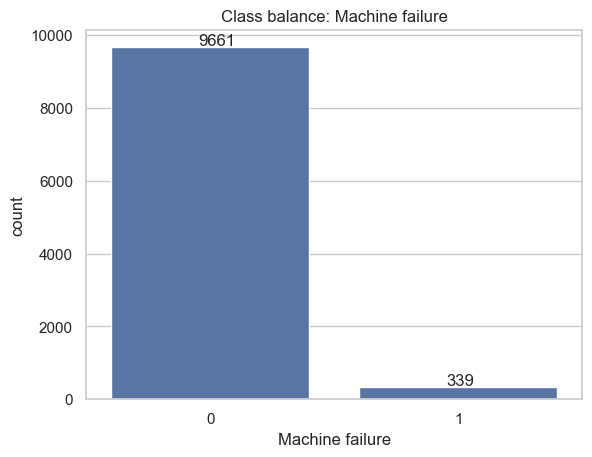

In [217]:
counts = df["Machine failure"].value_counts()
print(counts, "\n", (counts / len(df) * 100).round(2))

ax = sns.countplot(x="Machine failure", data=df)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x()+0.35, p.get_height()+50))
plt.title("Class balance: Machine failure")
plt.show()

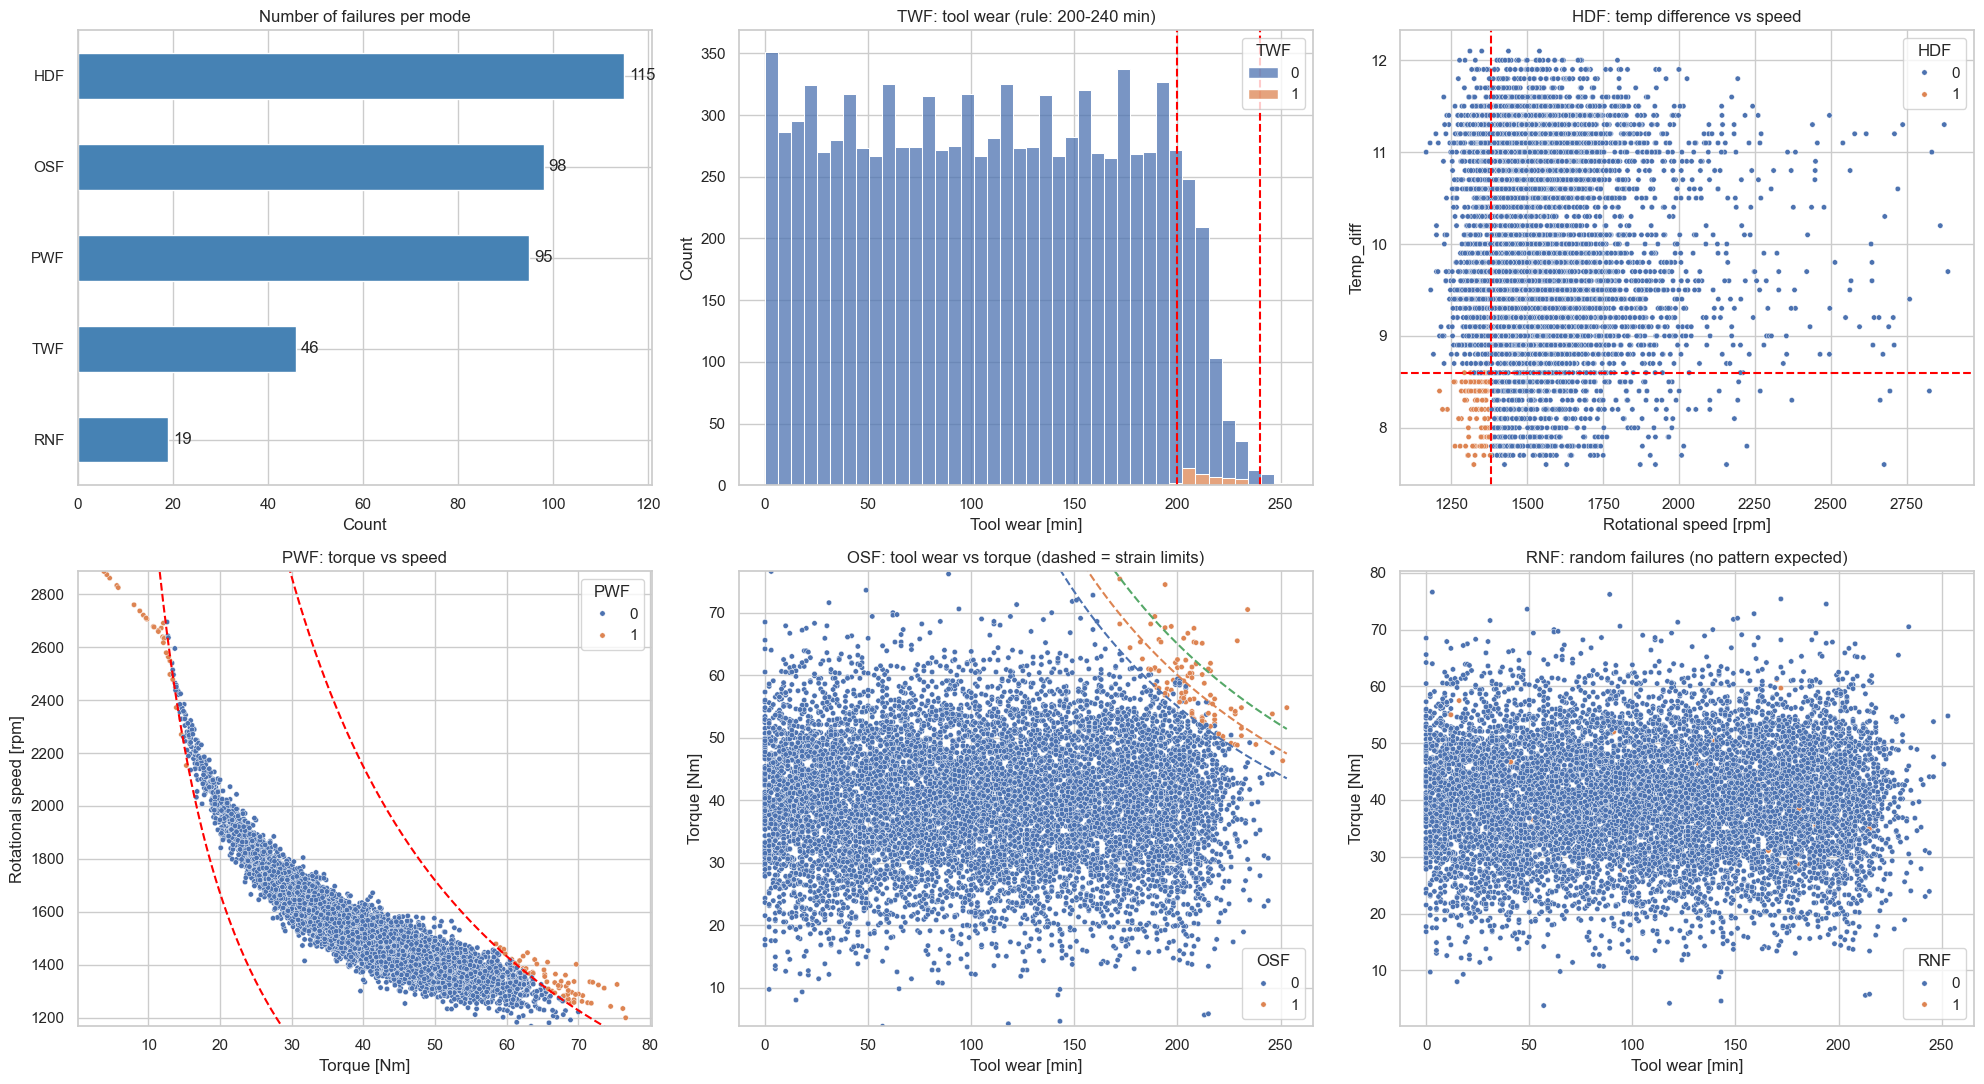

In [218]:
sns.set_theme(style="whitegrid")

# Original column names (no renaming needed)
air, proc = "Air temperature [K]", "Process temperature [K]"
rpm, tq, wear = "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"
modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]

# Helper features that mirror the failure rules
df["Temp_diff"] = df[proc] - df[air]
df["Power"] = df[tq] * df[rpm] * 2 * np.pi / 60
df["Strain"] = df[wear] * df[tq]

fig, axes = plt.subplots(2, 3, figsize=(20, 11))
axes = axes.flatten()

# 1) Count of each failure mode
counts = df[modes].sum().sort_values()
counts.plot(kind="barh", ax=axes[0], color="steelblue")
for i, v in enumerate(counts):
    axes[0].text(v + 1, i, int(v), va="center")
axes[0].set_title("Number of failures per mode")
axes[0].set_xlabel("Count")

# 2) TWF: tool wear (failures expected between 200 and 240 min)
sns.histplot(data=df, x=wear, hue="TWF", bins=40, multiple="stack", ax=axes[1])
axes[1].axvline(200, color="red", ls="--"); axes[1].axvline(240, color="red", ls="--")
axes[1].set_title("TWF: tool wear (rule: 200-240 min)")

# 3) HDF: temperature difference < 8.6 K and speed < 1380 rpm
sns.scatterplot(data=df, x=rpm, y="Temp_diff", hue="HDF", s=15, ax=axes[2])
axes[2].axhline(8.6, color="red", ls="--"); axes[2].axvline(1380, color="red", ls="--")
axes[2].set_title("HDF: temp difference vs speed")

# 4) PWF: power < 3500 W or > 9000 W
sns.scatterplot(data=df, x=tq, y=rpm, hue="PWF", s=15, ax=axes[3])
axes[3].set_title("PWF: torque vs speed")
axes[3].set_ylim(df[rpm].min(), df[rpm].max())
# power-threshold curves: rpm = P * 60 / (2*pi*torque)
t = np.linspace(max(df[tq].min(), 1), df[tq].max(), 300)
for P in (3500, 9000):
    axes[3].plot(t, P * 60 / (2 * np.pi * t), color="red", ls="--")

# 5) OSF: strain above 11000 (L), 12000 (M), 13000 (H)
sns.scatterplot(data=df, x=wear, y=tq, hue="OSF", s=15, ax=axes[4])
w = np.linspace(max(df[wear].min(), 1), df[wear].max(), 300)
for lim in (11000, 12000, 13000):
    axes[4].plot(w, lim / w, ls="--", label=f"{lim}")
axes[4].set_ylim(df[tq].min(), df[tq].max())
axes[4].set_title("OSF: tool wear vs torque (dashed = strain limits)")

# 6) RNF: random by design, so no rule region is expected
sns.scatterplot(data=df, x=wear, y=tq, hue="RNF", s=15, ax=axes[5])
axes[5].set_title("RNF: random failures (no pattern expected)")

plt.tight_layout()
plt.show()

In [219]:
print(np.unique(df['Machine failure']))

[0 1]


## 3. Pre-processing

Select the usable predictor columns, encode machine type, define the target, and create a stratified train/test split. Feature selectors are fitted on the training data only; the test set is reserved for final evaluation.


In [220]:
features = ['Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]']
# drop : UID, Product ID, 'TWF', 'HDF', 'PWF', 'OSF', 'RNF' -> the five last columns are about the type of Machine failure

x = df[features].copy()
y = df["Machine failure"]
print(x.shape)
print(y.shape)

(10000, 6)
(10000,)


In [221]:
# change from str to int64
x["Type"] = x["Type"].map({"L": 0, "M": 1, "H": 2})

In [222]:
display(x)

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,1,298.1,308.6,1551,42.8,0
1,0,298.2,308.7,1408,46.3,3
2,0,298.1,308.5,1498,49.4,5
3,0,298.2,308.6,1433,39.5,7
4,0,298.2,308.7,1408,40.0,9
...,...,...,...,...,...,...
9995,1,298.8,308.4,1604,29.5,14
9996,2,298.9,308.4,1632,31.8,17
9997,1,299.0,308.6,1645,33.4,22
9998,2,299.0,308.7,1408,48.5,25


In [223]:
print(x["Type"].unique())   # Option A: should show [1 0 2], no NaN
print(x.dtypes)             # no 'object' columns left
print(x.isna().sum())       # all zeros

[1 0 2]
Type                         int64
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
dtype: object
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
dtype: int64


In [224]:
from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    RepeatedStratifiedKFold,
    cross_validate,
)


In [225]:
print(y_train.value_counts())
print(y_test.value_counts())

Machine failure
0    7729
1     271
Name: count, dtype: int64
Machine failure
0    1932
1      68
Name: count, dtype: int64


## 4. Modelling and evaluation setup

The models compared in this notebook are:

- Support Vector Classifier (SVC)
- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosting Classifier
- Neural Network MLP

All compact comparison experiments use the same model list and the same five-feature target where feature selection is used.


### 4.1 Experimental rules

- **No feature selection** is the reference baseline.
- ANOVA, Pearson correlation, RFE, forward selection, and backward selection retain **five features** so the first comparison is controlled.
- Lasso first identifies non-zero coefficients; the five strongest non-zero coefficients are used for the controlled comparison.
- Selectors are fitted on the training set only.
- The compact comparison uses a fixed random state and class balancing where the estimator supports `class_weight="balanced"`.
- The test-set results in this section are exploratory. After choosing the top three combinations, use cross-validation on the training data and evaluate the final models on the test set once.

### 4.2 Metrics

Accuracy is not the main ranking metric because failures are relatively uncommon. Results are ranked by:

1. **Failure recall**: how many actual failures were detected.
2. **Failure F1-score**: balance between failure recall and precision.
3. **Accuracy**: final tie-breaker.

The tables also show balanced accuracy, missed failures (false negatives), and false alarms (false positives).


In [226]:
from sklearn.feature_selection import SelectKBest, f_classif, RFE, SelectFromModel, SequentialFeatureSelector
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, balanced_accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression


In [227]:
def model_eval(y_predict, y_test):
    print(classification_report(y_test, y_predict, target_names=["No failure", "Failure"], digits=3))
    cm = confusion_matrix(y_test, y_predict)
    ConfusionMatrixDisplay(cm, display_labels=["No failure", "Failure"]).plot(cmap="Blues")
    plt.title("Confusion matrix (test set)")
    plt.grid(False)
    plt.show()

    tn, fp, fn, tp = cm.ravel()
    print(f"Missed failures (FN): {fn} | False alarms (FP): {fp} | Caught failures (TP): {tp}")

In [228]:
# Shared models for every compact feature-selection comparison.
RANDOM_STATE = 55
NUMBER_OF_FEATURES = 5

selection_models = {
    "SVC": make_pipeline(
        StandardScaler(),
        SVC(kernel="linear", class_weight="balanced")
    ),
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000, class_weight="balanced",
            random_state=RANDOM_STATE
        )
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=RANDOM_STATE
    ),
    "MLP": make_pipeline(
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=(64, 16),
            max_iter=1000,
            random_state=RANDOM_STATE
        )
    ),
}

def evaluate_selected_features(selection_name, selected_features):
    """Evaluate the same model list using one selected feature set."""
    rows = []
    for model_name, model in selection_models.items():
        model.fit(x_train[selected_features], y_train)
        predictions = model.predict(x_test[selected_features])
        report = classification_report(
            y_test, predictions, output_dict=True, zero_division=0
        )
        tn, fp, fn, tp = confusion_matrix(
            y_test, predictions, labels=[0, 1]
        ).ravel()
        rows.append({
            "Feature selection": selection_name,
            "Features": ", ".join(selected_features),
            "Model": model_name,
            "Accuracy": report["accuracy"],
            "Balanced accuracy": balanced_accuracy_score(y_test, predictions),
            "Failure precision": report["1"]["precision"],
            "Failure recall": report["1"]["recall"],
            "Failure F1": report["1"]["f1-score"],
            "Missed failures": fn,
            "False alarms": fp,
        })
    return pd.DataFrame(rows)

number_of_features = NUMBER_OF_FEATURES


## 5. No feature selection: baseline

Start with all available predictors. This baseline shows the performance of each model before any feature-selection method is applied.


              precision    recall  f1-score   support

  No failure      0.966     1.000     0.983      1932
     Failure      1.000     0.015     0.029        68

    accuracy                          0.967      2000
   macro avg      0.983     0.507     0.506      2000
weighted avg      0.968     0.967     0.951      2000



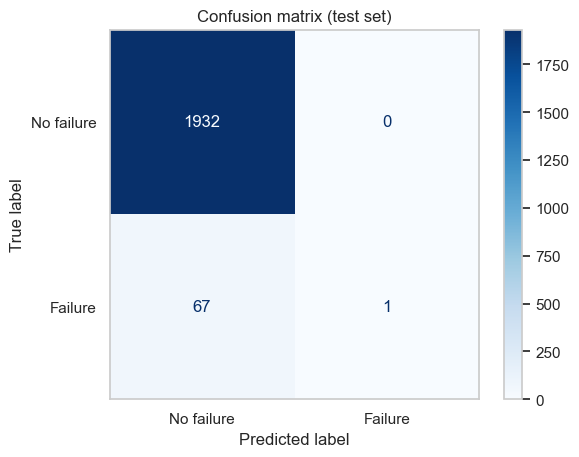

Missed failures (FN): 67 | False alarms (FP): 0 | Caught failures (TP): 1


In [229]:
svc = SVC()
svc.fit(x_train, y_train)
y_predict = svc.predict(x_test)
model_eval(y_predict, y_test)

              precision    recall  f1-score   support

  No failure      0.990     0.987     0.988      1932
     Failure      0.649     0.706     0.676        68

    accuracy                          0.977      2000
   macro avg      0.819     0.846     0.832      2000
weighted avg      0.978     0.977     0.977      2000



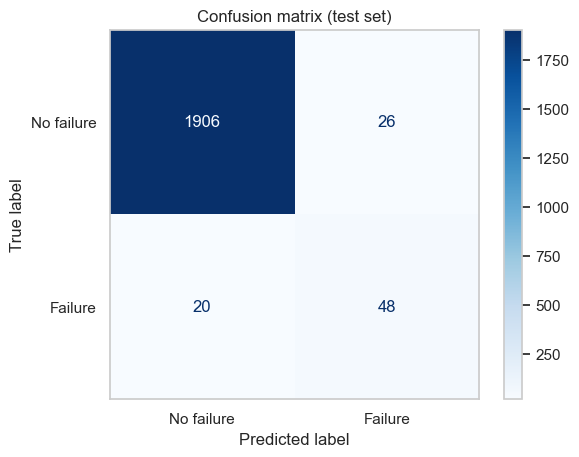

Missed failures (FN): 20 | False alarms (FP): 26 | Caught failures (TP): 48


In [230]:
dtc = DecisionTreeClassifier()
dtc.fit(x_train, y_train)
y_predict = dtc.predict(x_test)
model_eval(y_predict, y_test)

              precision    recall  f1-score   support

  No failure      0.990     0.998     0.994      1932
     Failure      0.925     0.721     0.810        68

    accuracy                          0.989      2000
   macro avg      0.957     0.859     0.902      2000
weighted avg      0.988     0.989     0.988      2000



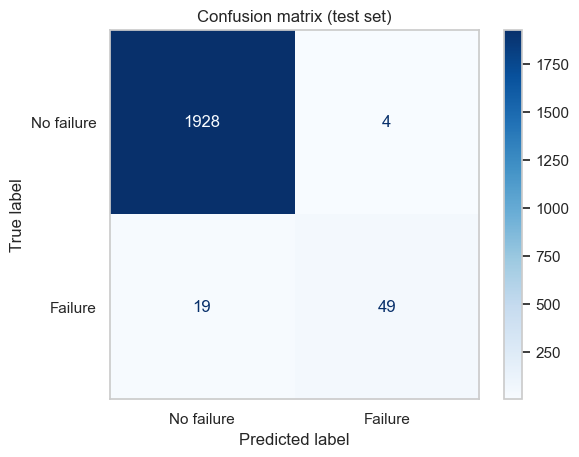

Missed failures (FN): 19 | False alarms (FP): 4 | Caught failures (TP): 49


In [231]:
rfc = RandomForestClassifier()
rfc.fit(x_train, y_train)
y_predict = rfc.predict(x_test)
model_eval(y_predict, y_test)

              precision    recall  f1-score   support

  No failure      0.985     0.976     0.980      1932
     Failure      0.453     0.574     0.506        68

    accuracy                          0.962      2000
   macro avg      0.719     0.775     0.743      2000
weighted avg      0.967     0.962     0.964      2000



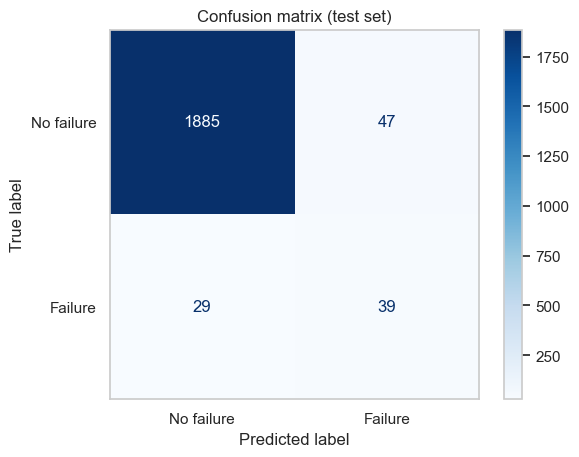

Missed failures (FN): 29 | False alarms (FP): 47 | Caught failures (TP): 39


In [232]:
mlp = MLPClassifier(hidden_layer_sizes=(64, 16), max_iter=1000)
mlp.fit(x_train, y_train)
y_predict = mlp.predict(x_test)
model_eval(y_predict, y_test)

              precision    recall  f1-score   support

  No failure      0.974     0.996     0.985      1932
     Failure      0.696     0.235     0.352        68

    accuracy                          0.971      2000
   macro avg      0.835     0.616     0.668      2000
weighted avg      0.964     0.971     0.963      2000



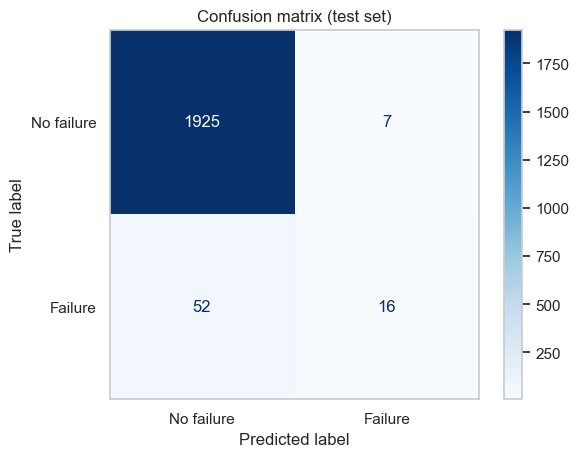

Missed failures (FN): 52 | False alarms (FP): 7 | Caught failures (TP): 16


In [233]:
lr = LogisticRegression()
lr.fit(x_train, y_train)
y_predict = lr.predict(x_test)
model_eval(y_predict, y_test)

In [234]:
# Compact baseline table using all predictor columns.
baseline_results = evaluate_selected_features(
    "No feature selection", x_train.columns.tolist()
)
display(
    baseline_results.sort_values(
        ["Failure recall", "Failure F1", "Accuracy"],
        ascending=False,
    )
)


,Feature selection,Features,Model,Accuracy,Balanced accuracy,Failure precision,Failure recall,Failure F1,Missed failures,False alarms
0,No feature selection,"Type, Air temperature [K], Process temperature...",SVC,0.8300,0.826879,0.145833,0.823529,0.247788,12,328
1,No feature selection,"Type, Air temperature [K], Process temperature...",Logistic Regression,0.8230,0.823255,0.140704,0.823529,0.240343,12,342
5,No feature selection,"Type, Air temperature [K], Process temperature...",MLP,0.9835,0.870859,0.761194,0.750000,0.755556,17,16
4,No feature selection,"Type, Air temperature [K], Process temperature...",Gradient Boosting,0.9845,0.835906,0.836364,0.676471,0.747967,22,9
2,No feature selection,"Type, Air temperature [K], Process temperature...",Decision Tree,0.9780,0.811259,0.693548,0.632353,0.661538,25,19
3,No feature selection,"Type, Air temperature [K], Process temperature...",Random Forest,0.9835,0.785730,0.906977,0.573529,0.702703,29,4


## 6. Filter methods

Filter methods score features before a model is trained. They are fast and model-independent.

### 6.1 ANOVA filter selection

ANOVA scores each feature independently against the target and keeps the top five features.


Features kept: 5
Selected: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
              precision    recall  f1-score   support

  No failure      0.989     0.986     0.987      1932
     Failure      0.630     0.676     0.652        68

    accuracy                          0.976      2000
   macro avg      0.809     0.831     0.820      2000
weighted avg      0.976     0.976     0.976      2000



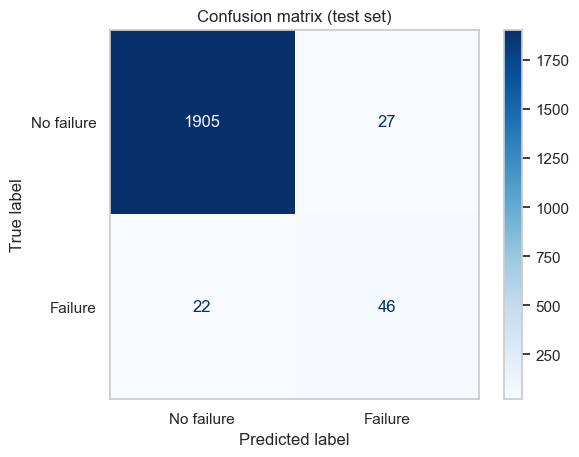

Missed failures (FN): 22 | False alarms (FP): 27 | Caught failures (TP): 46


In [235]:
anova_filter = SelectKBest(f_classif, k = 5)
anova_svc = make_pipeline(StandardScaler(), anova_filter, SVC(kernel='linear'))
anova_svc.fit(x_train, y_train)

selector = anova_svc.named_steps["selectkbest"]     # or anova_svc[0]

mask = selector.get_support()
print("Features kept:", mask.sum())
print("Selected:", x_train.columns[mask].tolist())
y_predict = anova_dtc.predict(x_test)
model_eval(y_predict, y_test)

Features kept: 5
Selected: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
              precision    recall  f1-score   support

  No failure      0.988     0.987     0.988      1932
     Failure      0.643     0.662     0.652        68

    accuracy                          0.976      2000
   macro avg      0.815     0.824     0.820      2000
weighted avg      0.976     0.976     0.976      2000



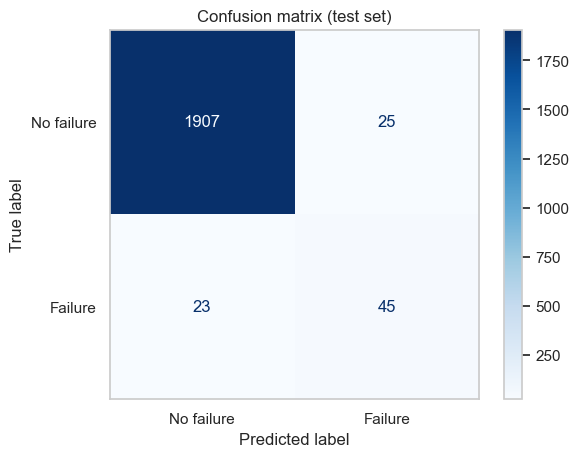

Missed failures (FN): 23 | False alarms (FP): 25 | Caught failures (TP): 45


In [236]:
anova_dtc = make_pipeline(StandardScaler(), anova_filter, DecisionTreeClassifier())
anova_dtc.fit(x_train, y_train)

selector = anova_dtc.named_steps["selectkbest"]     # or anova_svc[0]

mask = selector.get_support()
print("Features kept:", mask.sum())
print("Selected:", x_train.columns[mask].tolist())
y_predict = anova_dtc.predict(x_test)
model_eval(y_predict, y_test)


Features kept: 5
Selected: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
              precision    recall  f1-score   support

  No failure      0.989     0.997     0.993      1932
     Failure      0.887     0.691     0.777        68

    accuracy                          0.987      2000
   macro avg      0.938     0.844     0.885      2000
weighted avg      0.986     0.987     0.986      2000



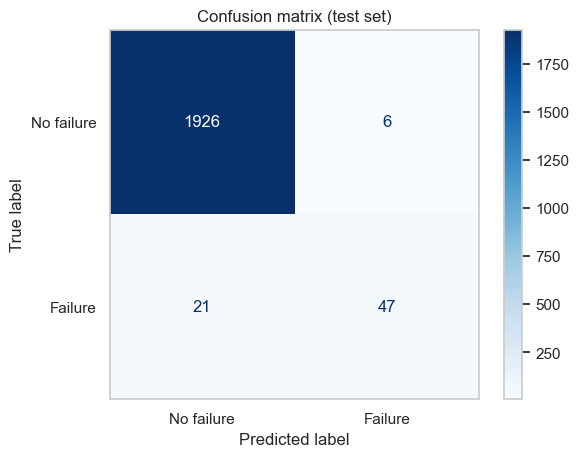

Missed failures (FN): 21 | False alarms (FP): 6 | Caught failures (TP): 47


In [237]:
anova_rfc = make_pipeline(StandardScaler(), anova_filter, RandomForestClassifier())
anova_rfc.fit(x_train, y_train)

selector = anova_rfc.named_steps["selectkbest"]     # or anova_svc[0]

mask = selector.get_support()
print("Features kept:", mask.sum())
print("Selected:", x_train.columns[mask].tolist())
y_predict = anova_rfc.predict(x_test)
model_eval(y_predict, y_test)


Features kept: 5
Selected: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
              precision    recall  f1-score   support

  No failure      0.991     0.994     0.992      1932
     Failure      0.806     0.735     0.769        68

    accuracy                          0.985      2000
   macro avg      0.899     0.865     0.881      2000
weighted avg      0.984     0.985     0.985      2000



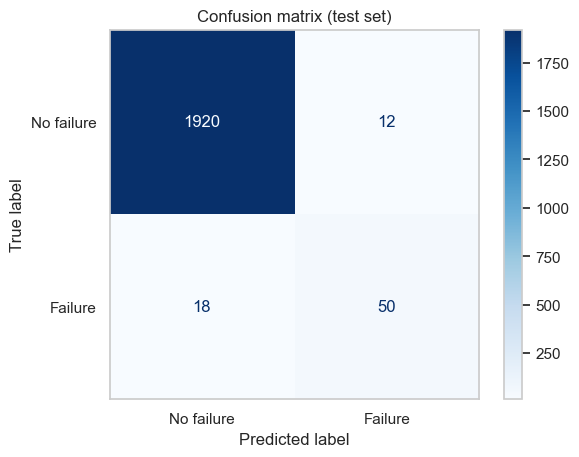

Missed failures (FN): 18 | False alarms (FP): 12 | Caught failures (TP): 50


In [238]:
anova_mlp = make_pipeline(StandardScaler(), anova_filter, MLPClassifier(hidden_layer_sizes=(64, 16), max_iter=1000, random_state = 55)) # try: 8, 8 - 16, 8 - 16, 16
anova_mlp.fit(x_train, y_train)

selector = anova_mlp.named_steps["selectkbest"]     # or anova_svc[0]

mask = selector.get_support()
print("Features kept:", mask.sum())
print("Selected:", x_train.columns[mask].tolist())
y_predict = anova_mlp.predict(x_test)
model_eval(y_predict, y_test)


Features kept: 5
Selected: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
              precision    recall  f1-score   support

  No failure      0.974     0.997     0.985      1932
     Failure      0.762     0.235     0.360        68

    accuracy                          0.972      2000
   macro avg      0.868     0.616     0.672      2000
weighted avg      0.967     0.972     0.964      2000



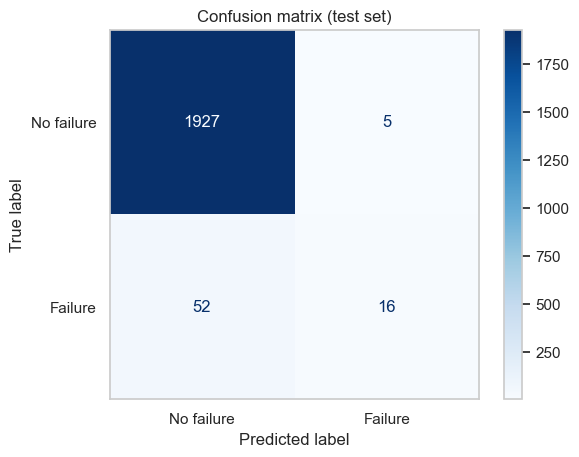

Missed failures (FN): 52 | False alarms (FP): 5 | Caught failures (TP): 16


In [239]:
anova_lr = make_pipeline(StandardScaler(), anova_filter, LogisticRegression())
anova_lr.fit(x_train, y_train)

selector = anova_lr.named_steps["selectkbest"]     # or anova_svc[0]

mask = selector.get_support()
print("Features kept:", mask.sum())
print("Selected:", x_train.columns[mask].tolist())
y_predict = anova_lr.predict(x_test)
model_eval(y_predict, y_test)


In [240]:
# Compact ANOVA comparison using the features selected by SelectKBest.
anova_features = x_train.columns[anova_filter.get_support()].tolist()
anova_results = evaluate_selected_features("ANOVA", anova_features)
print("ANOVA-selected features:", anova_features)
display(anova_results.sort_values("Failure F1", ascending=False))


ANOVA-selected features: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


,Feature selection,Features,Model,Accuracy,Balanced accuracy,Failure precision,Failure recall,Failure F1,Missed failures,False alarms
4,ANOVA,"Air temperature [K], Process temperature [K], ...",Gradient Boosting,0.9865,0.844035,0.886792,0.691176,0.776860,21,6
5,ANOVA,"Air temperature [K], Process temperature [K], ...",MLP,0.9850,0.864541,0.806452,0.735294,0.769231,18,12
3,ANOVA,"Air temperature [K], Process temperature [K], ...",Random Forest,0.9845,0.807530,0.893617,0.617647,0.730435,26,5
2,ANOVA,"Air temperature [K], Process temperature [K], ...",Decision Tree,0.9755,0.795777,0.650794,0.602941,0.625954,27,22
0,ANOVA,"Air temperature [K], Process temperature [K], ...",SVC,0.8370,0.830502,0.151351,0.823529,0.255708,12,314
1,ANOVA,"Air temperature [K], Process temperature [K], ...",Logistic Regression,0.8250,0.824291,0.142132,0.823529,0.242424,12,338


### 6.2 Pearson correlation selection

Pearson correlation selects the five features with the strongest absolute linear relationship with the binary target.


In [241]:
# Pearson correlation selection
# Score features on the training set only and keep the strongest absolute relationships.
correlation_scores = x_train.apply(
    lambda column: abs(np.corrcoef(column, y_train)[0, 1])
).sort_values(ascending=False)
correlation_features = correlation_scores.head(number_of_features).index.tolist()

print("Selected features:", correlation_features)
display(correlation_scores.to_frame("absolute Pearson correlation"))

correlation_results = evaluate_selected_features(
    "Pearson correlation", correlation_features
)
display(correlation_results.sort_values("Failure F1", ascending=False))


Selected features: ['Torque [Nm]', 'Tool wear [min]', 'Air temperature [K]', 'Rotational speed [rpm]', 'Process temperature [K]']


,absolute Pearson correlation
Torque [Nm],0.186876
Tool wear [min],0.102361
Air temperature [K],0.087332
Rotational speed [rpm],0.040933
Process temperature [K],0.038336
Type,0.033911


,Feature selection,Features,Model,Accuracy,Balanced accuracy,Failure precision,Failure recall,Failure F1,Missed failures,False alarms
4,Pearson correlation,"Torque [Nm], Tool wear [min], Air temperature ...",Gradient Boosting,0.9865,0.844035,0.886792,0.691176,0.776860,21,6
5,Pearson correlation,"Torque [Nm], Tool wear [min], Air temperature ...",MLP,0.9850,0.871636,0.796875,0.750000,0.772727,17,13
3,Pearson correlation,"Torque [Nm], Tool wear [min], Air temperature ...",Random Forest,0.9835,0.785730,0.906977,0.573529,0.702703,29,4
2,Pearson correlation,"Torque [Nm], Tool wear [min], Air temperature ...",Decision Tree,0.9745,0.795259,0.630769,0.602941,0.616541,27,24
0,Pearson correlation,"Torque [Nm], Tool wear [min], Air temperature ...",SVC,0.8370,0.830502,0.151351,0.823529,0.255708,12,314
1,Pearson correlation,"Torque [Nm], Tool wear [min], Air temperature ...",Logistic Regression,0.8250,0.824291,0.142132,0.823529,0.242424,12,338


## 7. Embedded methods

Embedded methods select features while fitting a model.

### 7.1 Adapted Lasso selection

Lasso uses L1 regularization. It can shrink coefficients to zero, so coefficient size can be used for feature selection.


In [242]:
# Adapted Lasso selection
adapted_lasso = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        penalty="l1", solver="liblinear", C=0.1,
        max_iter=2000, random_state=RANDOM_STATE
    )
)
adapted_lasso.fit(x_train, y_train)

lasso_coefficients = np.abs(adapted_lasso[-1].coef_).ravel()
nonzero_lasso = np.flatnonzero(lasso_coefficients > 1e-8)
strongest_lasso = np.argsort(lasso_coefficients)[::-1]
lasso_indices = [
    index for index in strongest_lasso if index in nonzero_lasso
][:number_of_features]
if lasso_indices:
    lasso_features = x_train.columns[lasso_indices].tolist()
else:
    # If the penalty removes every coefficient, use the five largest coefficients.
    lasso_features = x_train.columns[
        np.argsort(lasso_coefficients)[-number_of_features:]
    ].tolist()

print("Selected features:", lasso_features)
display(
    pd.Series(lasso_coefficients, index=x_train.columns)
    .sort_values(ascending=False)
    .to_frame("absolute L1 coefficient")
)

lasso_results = evaluate_selected_features(
    "Adapted Lasso", lasso_features
)
display(lasso_results.sort_values("Failure F1", ascending=False))



Selected features: ['Torque [Nm]', 'Rotational speed [rpm]', 'Air temperature [K]', 'Tool wear [min]', 'Process temperature [K]']


,absolute L1 coefficient
Torque [Nm],2.362645
Rotational speed [rpm],1.736399
Air temperature [K],1.072223
Tool wear [min],0.669434
Process temperature [K],0.659925
Type,0.125341


,Feature selection,Features,Model,Accuracy,Balanced accuracy,Failure precision,Failure recall,Failure F1,Missed failures,False alarms
4,Adapted Lasso,"Torque [Nm], Rotational speed [rpm], Air tempe...",Gradient Boosting,0.9865,0.844035,0.886792,0.691176,0.776860,21,6
5,Adapted Lasso,"Torque [Nm], Rotational speed [rpm], Air tempe...",MLP,0.9830,0.863506,0.757576,0.735294,0.746269,18,16
3,Adapted Lasso,"Torque [Nm], Rotational speed [rpm], Air tempe...",Random Forest,0.9850,0.807788,0.913043,0.617647,0.736842,26,4
2,Adapted Lasso,"Torque [Nm], Rotational speed [rpm], Air tempe...",Decision Tree,0.9750,0.795518,0.640625,0.602941,0.621212,27,23
0,Adapted Lasso,"Torque [Nm], Rotational speed [rpm], Air tempe...",SVC,0.8370,0.830502,0.151351,0.823529,0.255708,12,314
1,Adapted Lasso,"Torque [Nm], Rotational speed [rpm], Air tempe...",Logistic Regression,0.8250,0.824291,0.142132,0.823529,0.242424,12,338


## 7.2 Ridge and Elastic Net comparison

Ridge (L2) usually shrinks coefficients but does not remove features, so it is a regularized-model comparison rather than a strict feature selector. Elastic Net combines L1 and L2 and can remove some features while handling correlated predictors. Both are included here to compare regularization choices before fine-tuning.


In [243]:
# Compare regularized Logistic Regression models using all original features.
regularization_models = {
    "Ridge (L2)": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="l2", class_weight="balanced",
            max_iter=2000, random_state=RANDOM_STATE
        )
    ),
    "Lasso (L1)": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="l1", solver="liblinear",
            class_weight="balanced", max_iter=2000,
            random_state=RANDOM_STATE
        )
    ),
    "Elastic Net": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty="elasticnet", solver="saga", l1_ratio=0.5,
            class_weight="balanced", max_iter=3000,
            random_state=RANDOM_STATE
        )
    ),
}

regularization_rows = []
for model_name, model in regularization_models.items():
    model.fit(x_train, y_train)
    predictions = model.predict(x_test)
    report = classification_report(
        y_test, predictions, output_dict=True, zero_division=0
    )
    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()
    regularization_rows.append({
        "Regularization": model_name,
        "Accuracy": report["accuracy"],
        "Balanced accuracy": balanced_accuracy_score(y_test, predictions),
        "Failure precision": report["1"]["precision"],
        "Failure recall": report["1"]["recall"],
        "Failure F1": report["1"]["f1-score"],
        "Missed failures": fn,
        "False alarms": fp,
    })

regularization_results = pd.DataFrame(regularization_rows).sort_values(
    ["Failure recall", "Failure F1", "Accuracy"],
    ascending=False,
)
display(regularization_results)


c:\Users\ROG\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


,Regularization,Accuracy,Balanced accuracy,Failure precision,Failure recall,Failure F1,Missed failures,False alarms
0,Ridge (L2),0.8230,0.823255,0.140704,0.823529,0.240343,12,342
1,Lasso (L1),0.8230,0.823255,0.140704,0.823529,0.240343,12,342
2,Elastic Net,0.8265,0.817973,0.141388,0.808824,0.240700,13,334


## 8. Wrapper methods

RFE, forward selection, and backward selection are related wrapper/model-based methods, but they are not duplicates:

- **RFE** removes features using estimator importance or coefficients.
- **Forward selection** starts with no features and adds the feature that improves cross-validation performance.
- **Backward selection** starts with all features and removes the feature whose removal hurts performance least.

### 8.1 Recursive Feature Elimination (RFE)

The compact comparison below tests several estimators as RFE selectors. The final RFE model comparison uses Logistic Regression for consistency.



In [244]:
# Compare supported estimators as RFE selectors.
rfe_selectors = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Linear SVC": SVC(
        kernel="linear", class_weight="balanced"
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
}

rfe_selected_features = {}
for selector_name, estimator in rfe_selectors.items():
    selector = RFE(
        estimator,
        n_features_to_select=number_of_features,
    )
    selector.fit(x_train, y_train)
    rfe_selected_features[selector_name] = (
        x_train.columns[selector.get_support()].tolist()
    )

display(pd.DataFrame.from_dict(
    rfe_selected_features,
    orient="index",
    columns=[f"Feature {i + 1}" for i in range(number_of_features)],
))


,Feature 1,Feature 2,Feature 3,Feature 4,Feature 5
Logistic Regression,Type,Air temperature [K],Process temperature [K],Torque [Nm],Tool wear [min]
Linear SVC,Type,Air temperature [K],Process temperature [K],Torque [Nm],Tool wear [min]
Decision Tree,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Random Forest,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]


In [245]:
# Compact RFE comparison using Logistic Regression as the selector.
rfe_comparison = RFE(
    LogisticRegression(
        max_iter=2000, class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    n_features_to_select=number_of_features,
)
rfe_comparison.fit(x_train, y_train)
rfe_features = x_train.columns[rfe_comparison.get_support()].tolist()
rfe_results = evaluate_selected_features("RFE", rfe_features)
print("RFE-selected features:", rfe_features)
display(rfe_results.sort_values("Failure F1", ascending=False))


RFE-selected features: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Torque [Nm]', 'Tool wear [min]']


,Feature selection,Features,Model,Accuracy,Balanced accuracy,Failure precision,Failure recall,Failure F1,Missed failures,False alarms
5,RFE,"Type, Air temperature [K], Process temperature...",MLP,0.9825,0.806494,0.823529,0.617647,0.705882,26,9
4,RFE,"Type, Air temperature [K], Process temperature...",Gradient Boosting,0.9770,0.746894,0.739130,0.500000,0.596491,34,12
3,RFE,"Type, Air temperature [K], Process temperature...",Random Forest,0.9735,0.695424,0.692308,0.397059,0.504673,41,12
2,RFE,"Type, Air temperature [K], Process temperature...",Decision Tree,0.9650,0.712307,0.483871,0.441176,0.461538,38,32
0,RFE,"Type, Air temperature [K], Process temperature...",SVC,0.8060,0.793174,0.124413,0.779412,0.214575,15,373
1,RFE,"Type, Air temperature [K], Process temperature...",Logistic Regression,0.7480,0.763153,0.097786,0.779412,0.173770,15,489


### 8.2 Forward and backward Sequential Feature Selection

Both methods evaluate feature groups using cross-validation and retain five features.


In [246]:
# Forward and backward wrapper selection
# Logistic Regression is used as the selector; the selected columns are
# then evaluated with every comparison model.
sfs_estimator = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=55)
)

forward_selector = SequentialFeatureSelector(
    sfs_estimator, n_features_to_select=number_of_features,
    direction="forward", scoring="f1", cv=5, n_jobs=-1
)
backward_selector = SequentialFeatureSelector(
    sfs_estimator, n_features_to_select=number_of_features,
    direction="backward", scoring="f1", cv=5, n_jobs=-1
)

forward_selector.fit(x_train, y_train)
backward_selector.fit(x_train, y_train)
forward_features = x_train.columns[forward_selector.get_support()].tolist()
backward_features = x_train.columns[backward_selector.get_support()].tolist()

print("Forward-selected features:", forward_features)
print("Backward-selected features:", backward_features)

forward_results = evaluate_selected_features("Forward selection", forward_features)
backward_results = evaluate_selected_features("Backward selection", backward_features)



Forward-selected features: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]']
Backward-selected features: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]']


## 9. Dimensionality reduction

### 9.1 PCA comparison

PCA is not direct feature selection. It creates new components instead of retaining the original machine variables, so its results are reported separately.


In [247]:
from sklearn.decomposition import PCA

[0.319 0.307 0.168 0.165 0.021 0.02 ]
[0.319 0.625 0.794 0.959 0.98  1.   ]


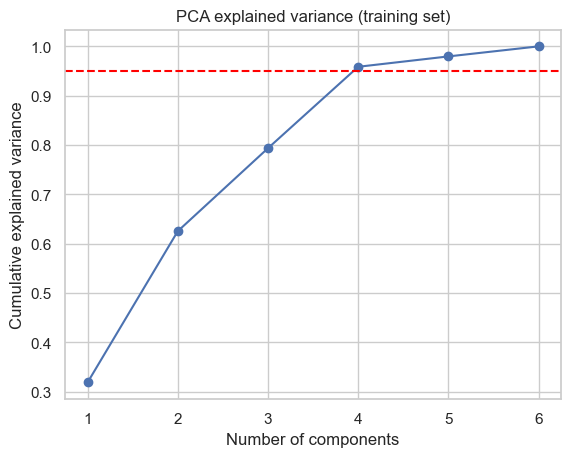

In [248]:
scaler = StandardScaler()
x_train_s = scaler.fit_transform(x_train)
x_test_s = scaler.transform(x_test)

pca_full = PCA(random_state=42).fit(x_train_s)
cum = np.cumsum(pca_full.explained_variance_ratio_)
print(np.round(pca_full.explained_variance_ratio_, 3))
print(np.round(cum, 3))

plt.plot(range(1, len(cum) + 1), cum, marker="o")
plt.axhline(0.95, color="red", ls="--")
plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance")
plt.title("PCA explained variance (training set)")
plt.show()

In [249]:
pca = PCA(n_components=0.95, random_state=42)   # keep enough components for 95% variance
x_train_pca = pca.fit_transform(x_train_s)
x_test_pca = pca.transform(x_test_s)
print("Components kept:", pca.n_components_)

Components kept: 4


              precision    recall  f1-score   support

  No failure      0.966     1.000     0.983      1932
     Failure      0.000     0.000     0.000        68

    accuracy                          0.966      2000
   macro avg      0.483     0.500     0.491      2000
weighted avg      0.933     0.966     0.949      2000



c:\Users\ROG\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ROG\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ROG\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


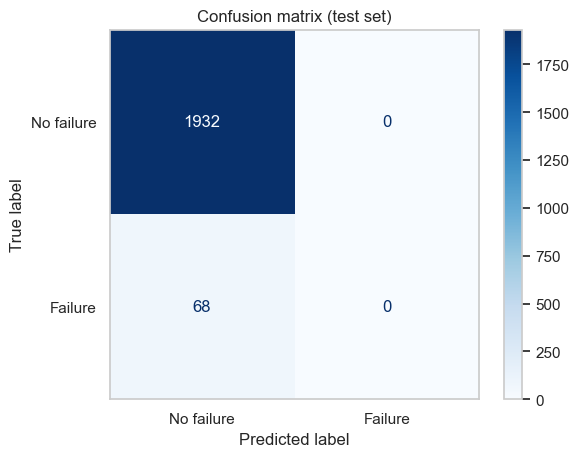

Missed failures (FN): 68 | False alarms (FP): 0 | Caught failures (TP): 0


In [250]:
svc = SVC(kernel = "linear")
svc.fit(x_train_pca, y_train)
y_predict = svc.predict(x_test_pca)
model_eval(y_predict, y_test)

              precision    recall  f1-score   support

  No failure      0.980     0.976     0.978      1932
     Failure      0.390     0.441     0.414        68

    accuracy                          0.958      2000
   macro avg      0.685     0.708     0.696      2000
weighted avg      0.960     0.958     0.959      2000



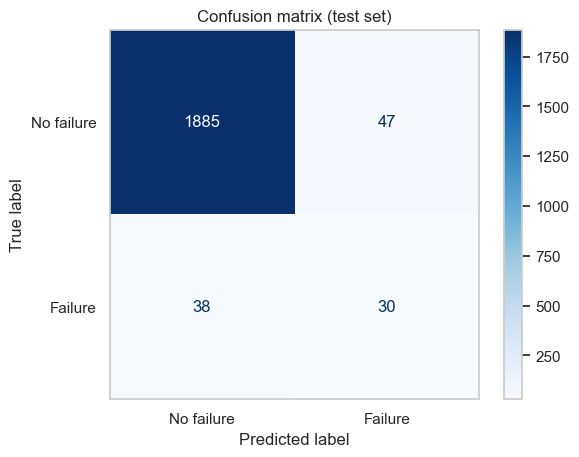

Missed failures (FN): 38 | False alarms (FP): 47 | Caught failures (TP): 30


In [251]:
dtc = DecisionTreeClassifier()
dtc.fit(x_train_pca, y_train)
y_predict = dtc.predict(x_test_pca)
model_eval(y_predict, y_test)

              precision    recall  f1-score   support

  No failure      0.975     0.995     0.985      1932
     Failure      0.679     0.279     0.396        68

    accuracy                          0.971      2000
   macro avg      0.827     0.637     0.690      2000
weighted avg      0.965     0.971     0.965      2000



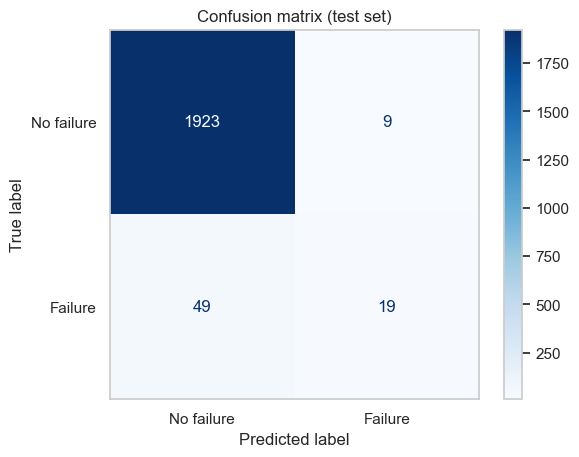

Missed failures (FN): 49 | False alarms (FP): 9 | Caught failures (TP): 19


In [252]:
rfc = RandomForestClassifier()
rfc.fit(x_train_pca, y_train)
y_predict = rfc.predict(x_test_pca)
model_eval(y_predict, y_test)

              precision    recall  f1-score   support

  No failure      0.978     0.998     0.988      1932
     Failure      0.862     0.368     0.515        68

    accuracy                          0.977      2000
   macro avg      0.920     0.683     0.752      2000
weighted avg      0.974     0.977     0.972      2000



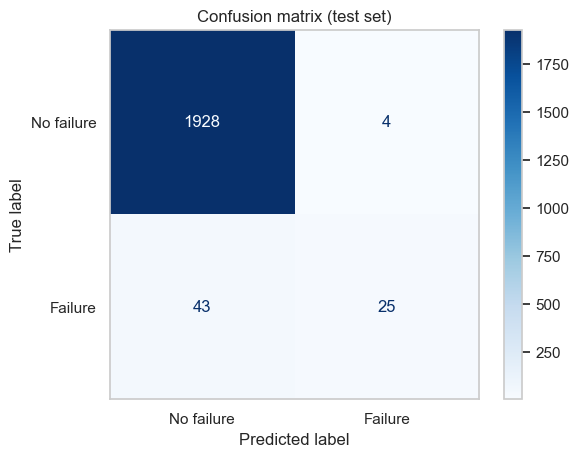

Missed failures (FN): 43 | False alarms (FP): 4 | Caught failures (TP): 25


In [253]:
mlp = MLPClassifier(hidden_layer_sizes=(64, 16), max_iter=1000)
mlp.fit(x_train_pca, y_train)
y_predict = mlp.predict(x_test_pca)
model_eval(y_predict, y_test)

              precision    recall  f1-score   support

  No failure      0.966     1.000     0.983      1932
     Failure      0.000     0.000     0.000        68

    accuracy                          0.966      2000
   macro avg      0.483     0.500     0.491      2000
weighted avg      0.933     0.966     0.949      2000



c:\Users\ROG\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ROG\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ROG\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


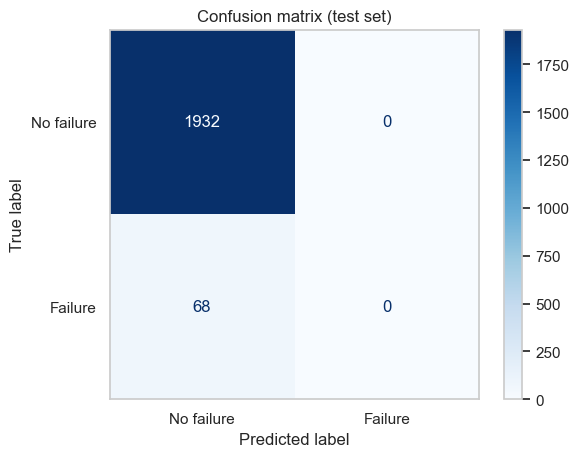

Missed failures (FN): 68 | False alarms (FP): 0 | Caught failures (TP): 0


In [254]:
lr = LogisticRegression()
lr.fit(x_train_pca, y_train)
y_predict = lr.predict(x_test_pca)
model_eval(y_predict, y_test)

## 10. Compare the experiments

The first table ranks models within each selection method. The second table keeps only the best model from each method.

Ranking priority:

1. Failure recall
2. Failure F1-score
3. Accuracy

This prioritizes detecting real failures, then balances missed failures and false alarms. Accuracy is used only as a tie-breaker because the target is imbalanced.


In [255]:
# Combine the compact results from the baseline and feature-selection methods.
all_comparison_results = pd.concat(
    [
        baseline_results,
        anova_results,
        correlation_results,
        lasso_results,
        forward_results,
        backward_results,
        rfe_results,
    ],
    ignore_index=True,
)

# Order the selection methods in the same order as the notebook.
selection_order = [
    "No feature selection",
    "ANOVA",
    "Pearson correlation",
    "Adapted Lasso",
    "RFE",
    "Forward selection",
    "Backward selection",
]
all_comparison_results["Feature selection"] = pd.Categorical(
    all_comparison_results["Feature selection"],
    categories=selection_order,
    ordered=True,
)

# Table 1: rank models within each feature-selection method.
grouped_ranking = all_comparison_results.sort_values(
    [
        "Feature selection",
        "Failure recall",
        "Failure F1",
        "Accuracy",
    ],
    ascending=[True, False, False, False],
).reset_index(drop=True)

print("Ranking within each feature-selection method:")
display(grouped_ranking)

# Table 2: keep only the best model from each selection method.
best_per_selection = (
    grouped_ranking.groupby(
        "Feature selection", observed=True, sort=False
    )
    .head(1)
    .reset_index(drop=True)
    .sort_values(
        ["Failure recall", "Failure F1", "Accuracy"],
        ascending=[False, False, False],
    )
    .reset_index(drop=True)
)

print("Best model from each feature-selection method:")
display(best_per_selection)


Ranking within each feature-selection method:


,Feature selection,Features,Model,Accuracy,Balanced accuracy,Failure precision,Failure recall,Failure F1,Missed failures,False alarms
0,No feature selection,"Type, Air temperature [K], Process temperature...",SVC,0.8300,0.826879,0.145833,0.823529,0.247788,12,328
1,No feature selection,"Type, Air temperature [K], Process temperature...",Logistic Regression,0.8230,0.823255,0.140704,0.823529,0.240343,12,342
2,No feature selection,"Type, Air temperature [K], Process temperature...",MLP,0.9835,0.870859,0.761194,0.750000,0.755556,17,16
3,No feature selection,"Type, Air temperature [K], Process temperature...",Gradient Boosting,0.9845,0.835906,0.836364,0.676471,0.747967,22,9
4,No feature selection,"Type, Air temperature [K], Process temperature...",Decision Tree,0.9780,0.811259,0.693548,0.632353,0.661538,25,19
5,No feature selection,"Type, Air temperature [K], Process temperature...",Random Forest,0.9835,0.785730,0.906977,0.573529,0.702703,29,4
6,ANOVA,"Air temperature [K], Process temperature [K], ...",SVC,0.8370,0.830502,0.151351,0.823529,0.255708,12,314
7,ANOVA,"Air temperature [K], Process temperature [K], ...",Logistic Regression,0.8250,0.824291,0.142132,0.823529,0.242424,12,338
8,ANOVA,"Air temperature [K], Process temperature [K], ...",MLP,0.9850,0.864541,0.806452,0.735294,0.769231,18,12
9,ANOVA,"Air temperature [K], Process temperature [K], ...",Gradient Boosting,0.9865,0.844035,0.886792,0.691176,0.776860,21,6


Best model from each feature-selection method:


,Feature selection,Features,Model,Accuracy,Balanced accuracy,Failure precision,Failure recall,Failure F1,Missed failures,False alarms
0,ANOVA,"Air temperature [K], Process temperature [K], ...",SVC,0.8370,0.830502,0.151351,0.823529,0.255708,12,314
1,Pearson correlation,"Torque [Nm], Tool wear [min], Air temperature ...",SVC,0.8370,0.830502,0.151351,0.823529,0.255708,12,314
2,Adapted Lasso,"Torque [Nm], Rotational speed [rpm], Air tempe...",SVC,0.8370,0.830502,0.151351,0.823529,0.255708,12,314
3,No feature selection,"Type, Air temperature [K], Process temperature...",SVC,0.8300,0.826879,0.145833,0.823529,0.247788,12,328
4,Forward selection,"Type, Air temperature [K], Process temperature...",SVC,0.8305,0.812949,0.142480,0.794118,0.241611,14,325
5,Backward selection,"Type, Air temperature [K], Process temperature...",SVC,0.8305,0.812949,0.142480,0.794118,0.241611,14,325
6,RFE,"Type, Air temperature [K], Process temperature...",SVC,0.8060,0.793174,0.124413,0.779412,0.214575,15,373


## 11. Extensive fine-tuning of the top three candidates

The exploratory comparison is now complete. Only the three strongest feature-selection/model combinations are carried forward.

This phase is deliberately more rigorous:

- Hyperparameters are searched with broader, model-specific grids.
- Five-fold cross-validation is repeated three times.
- F1-score is used to select parameters because it balances failure recall and precision.
- Accuracy, balanced accuracy, precision, recall, and F1-score are all recorded.
- The held-out test set is used only after tuning is complete.
- Cross-validation mean and standard deviation are reported to show stability.

The selected feature set is kept fixed during this tuning phase. For a later conference experiment, the selector itself should also be placed inside each cross-validation pipeline to measure selector uncertainty without leakage.


In [256]:
# Do not use the held-out test set to choose the candidates.
# Screen every existing candidate using training-only repeated CV instead.
screening_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=2,
    random_state=RANDOM_STATE,
)

candidate_screening_rows = []
for _, candidate in all_comparison_results.iterrows():
    selected_features = [
        feature.strip()
        for feature in candidate["Features"].split(",")
    ]
    model = clone(selection_models[candidate["Model"]])
    scores = cross_validate(
        model,
        x_train[selected_features],
        y_train,
        scoring={
            "f1": "f1",
            "recall": "recall",
            "balanced_accuracy": "balanced_accuracy",
        },
        cv=screening_cv,
        n_jobs=-1,
    )
    candidate_screening_rows.append({
        "Feature selection": candidate["Feature selection"],
        "Model": candidate["Model"],
        "Features": candidate["Features"],
        "Screening CV F1 mean": scores["test_f1"].mean(),
        "Screening CV F1 std": scores["test_f1"].std(),
        "Screening CV recall mean": scores["test_recall"].mean(),
        "Screening CV balanced accuracy mean": scores[
            "test_balanced_accuracy"
        ].mean(),
    })

candidate_screening_results = pd.DataFrame(candidate_screening_rows)
top_three_candidates = (
    candidate_screening_results
    .sort_values(
        [
            "Screening CV F1 mean",
            "Screening CV recall mean",
            "Screening CV balanced accuracy mean",
        ],
        ascending=[False, False, False],
    )
    .drop_duplicates(["Feature selection", "Model"])
    .head(3)
    .reset_index(drop=True)
)

print("Top three candidates selected using training-only repeated CV:")
display(top_three_candidates)


Top three candidates selected using training-only repeated CV:


,Feature selection,Model,Features,Screening CV F1 mean,Screening CV F1 std,Screening CV recall mean,Screening CV balanced accuracy mean
0,No feature selection,Gradient Boosting,"Type, Air temperature [K], Process temperature...",0.695375,0.063863,0.598249,0.797087
1,No feature selection,MLP,"Type, Air temperature [K], Process temperature...",0.695032,0.068172,0.622256,0.808314
2,Pearson correlation,Gradient Boosting,"Torque [Nm], Tool wear [min], Air temperature ...",0.681548,0.059154,0.583468,0.789567


In [257]:
def make_tuning_model(model_name):
    """Return a model and a broader, readable hyperparameter grid."""
    if model_name == "SVC":
        model = make_pipeline(
            StandardScaler(),
            SVC(class_weight="balanced"),
        )
        grid = [
            {
                "svc__kernel": ["linear"],
                "svc__C": [0.001, 0.01, 0.1, 1, 10, 100],
                "svc__class_weight": [None, "balanced"],
            },
            {
                "svc__kernel": ["rbf"],
                "svc__C": [0.01, 0.1, 1, 10, 100],
                "svc__gamma": ["scale", "auto", 0.001, 0.01, 0.1],
                "svc__class_weight": [None, "balanced"],
            },
        ]
    elif model_name == "Logistic Regression":
        model = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                max_iter=3000,
                random_state=RANDOM_STATE,
            ),
        )
        grid = [
            {
                "logisticregression__penalty": ["l1"],
                "logisticregression__solver": ["liblinear"],
                "logisticregression__C": [0.001, 0.01, 0.1, 1, 10, 100],
                "logisticregression__class_weight": [None, "balanced"],
            },
            {
                "logisticregression__penalty": ["l2"],
                "logisticregression__solver": ["lbfgs", "liblinear"],
                "logisticregression__C": [0.001, 0.01, 0.1, 1, 10, 100],
                "logisticregression__class_weight": [None, "balanced"],
            },
        ]
    elif model_name == "Decision Tree":
        model = DecisionTreeClassifier(
            random_state=RANDOM_STATE,
        )
        grid = {
            "criterion": ["gini", "entropy", "log_loss"],
            "class_weight": [None, "balanced"],
            "max_depth": [None, 3, 5, 8, 12],
            "min_samples_split": [2, 5, 10, 20],
            "min_samples_leaf": [1, 2, 5, 10],
            "max_features": [None, "sqrt", "log2"],
        }
    elif model_name == "Random Forest":
        model = RandomForestClassifier(
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
        grid = {
            "n_estimators": [200, 400, 800],
            "class_weight": [None, "balanced"],
            "criterion": ["gini", "entropy"],
            "max_depth": [None, 8, 16, 24],
            "min_samples_split": [2, 5, 10],
            "min_samples_leaf": [1, 2, 5],
            "max_features": ["sqrt", "log2", None],
        }
    elif model_name == "Gradient Boosting":
        model = GradientBoostingClassifier(
            random_state=RANDOM_STATE,
        )
        grid = {
            "n_estimators": [100, 200, 400],
            "learning_rate": [0.01, 0.03, 0.1, 0.2],
            "max_depth": [1, 2, 3, 5],
            "min_samples_split": [2, 5, 10],
            "min_samples_leaf": [1, 2, 5],
            "subsample": [0.7, 0.85, 1.0],
        }
    elif model_name == "MLP":
        model = make_pipeline(
            StandardScaler(),
            MLPClassifier(
                max_iter=2000,
                early_stopping=True,
                validation_fraction=0.15,
                random_state=RANDOM_STATE,
            ),
        )
        grid = {
            "mlpclassifier__hidden_layer_sizes": [
                (8,), (16,), (32,), (16, 8), (32, 16), (64, 32)
            ],
            "mlpclassifier__activation": ["relu", "tanh"],
            "mlpclassifier__alpha": [0.00001, 0.0001, 0.001, 0.01, 0.1],
            "mlpclassifier__learning_rate_init": [0.0001, 0.001, 0.01],
            "mlpclassifier__batch_size": [32, 64, 128],
        }
    else:
        raise ValueError(f"Unsupported model: {model_name}")
    return model, grid

cv_strategy = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=RANDOM_STATE,
)
scoring_metrics = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
}

tuned_models = []
for _, candidate in top_three_candidates.iterrows():
    selected_features = [
        feature.strip()
        for feature in candidate["Features"].split(",")
    ]
    model, parameter_grid = make_tuning_model(candidate["Model"])
    search = GridSearchCV(
        estimator=model,
        param_grid=parameter_grid,
        scoring=scoring_metrics,
        refit="f1",
        cv=cv_strategy,
        n_jobs=-1,
        return_train_score=True,
    )
    search.fit(x_train[selected_features], y_train)
    best_index = search.best_index_
    tuned_models.append({
        "Feature selection": candidate["Feature selection"],
        "Model": candidate["Model"],
        "Features": selected_features,
        "Search": search,
        "Best parameters": search.best_params_,
        "CV F1 mean": search.cv_results_["mean_test_f1"][best_index],
        "CV F1 std": search.cv_results_["std_test_f1"][best_index],
        "CV recall mean": search.cv_results_["mean_test_recall"][best_index],
        "CV precision mean": search.cv_results_["mean_test_precision"][best_index],
        "CV balanced accuracy mean": search.cv_results_[
            "mean_test_balanced_accuracy"
        ][best_index],
        "CV train F1 mean": search.cv_results_[
            "mean_train_f1"
        ][best_index],
        "Number of grid combinations": len(search.cv_results_["params"]),
    })

tuning_results = pd.DataFrame([
    {
        key: result[key]
        for key in [
            "Feature selection",
            "Model",
            "Features",
            "CV F1 mean",
            "CV F1 std",
            "CV recall mean",
            "CV precision mean",
            "CV balanced accuracy mean",
            "CV train F1 mean",
            "Number of grid combinations",
            "Best parameters",
        ]
    }
    for result in tuned_models
]).sort_values(
    ["CV F1 mean", "CV recall mean", "CV balanced accuracy mean"],
    ascending=False,
).reset_index(drop=True)

print("Repeated cross-validation tuning results:")
display(tuning_results)



KeyboardInterrupt: 

In [ ]:
def evaluate_final_candidate(result):
    """Evaluate one tuned candidate once on the held-out test set."""
    predictions = result["Search"].best_estimator_.predict(
        x_test[result["Features"]]
    )
    report = classification_report(
        y_test, predictions, output_dict=True, zero_division=0
    )
    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()
    return {
        "Feature selection": result["Feature selection"],
        "Model": result["Model"],
        "Features": ", ".join(result["Features"]),
        "CV F1 mean": result["CV F1 mean"],
        "CV F1 std": result["CV F1 std"],
        "Test accuracy": report["accuracy"],
        "Test balanced accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "Test failure precision": report["1"]["precision"],
        "Test failure recall": report["1"]["recall"],
        "Test failure F1": report["1"]["f1-score"],
        "Test missed failures": fn,
        "Test false alarms": fp,
    }

tuned_test_results = pd.DataFrame(
    [evaluate_final_candidate(result) for result in tuned_models]
).sort_values(
    ["CV F1 mean", "Test failure recall", "Test failure F1"],
    ascending=False,
).reset_index(drop=True)

print("Tuned top-three candidates on the untouched test set:")
display(tuned_test_results)

final_winner = tuned_test_results.iloc[0]
print("Final selected candidate:")
display(final_winner.to_frame("Value"))


Tuned top-three candidates on the held-out test set:


,Feature selection,Model,Features,Best CV F1,Test accuracy,Test balanced accuracy,Test failure precision,Test failure recall,Test failure F1,Test missed failures,Test false alarms
0,ANOVA,SVC,"Air temperature [K], Process temperature [K], ...",0.241482,0.8375,0.830761,0.151762,0.823529,0.256293,12,313
1,Pearson correlation,SVC,"Torque [Nm], Tool wear [min], Air temperature ...",0.241482,0.8375,0.830761,0.151762,0.823529,0.256293,12,313
2,Adapted Lasso,SVC,"Torque [Nm], Rotational speed [rpm], Air tempe...",0.241482,0.8375,0.830761,0.151762,0.823529,0.256293,12,313


Final selected candidate:


,Value
Feature selection,ANOVA
Model,SVC
Features,"Air temperature [K], Process temperature [K], ..."
Best CV F1,0.241482
Test accuracy,0.8375
Test balanced accuracy,0.830761
Test failure precision,0.151762
Test failure recall,0.823529
Test failure F1,0.256293
Test missed failures,12


## 12. Final model conclusion

The final model is selected primarily using repeated cross-validation F1-score. The standard deviation is reported because a high mean with high variability may be less reliable than a slightly lower but more stable result.

The held-out test results are reported only after tuning:

- Failure recall and missed failures show safety performance.
- Failure precision and false alarms show the operational cost of alerts.
- Balanced accuracy is more informative than ordinary accuracy for this imbalanced target.

For a conference paper, report the complete search space, cross-validation design, random seed, selected parameters, mean +/- standard deviation, and one final test-set evaluation. Avoid repeatedly changing the model after inspecting the test results.


## 13. Conclusion and next step

Summarize the complete experiment:

- The no-selection baseline.
- The strongest feature-selection methods.
- The three candidates selected for fine-tuning.
- The best hyperparameters found by cross-validation.
- The final model's test-set recall, F1-score, balanced accuracy, missed failures, and false alarms.
- Why the final model is appropriate for predictive maintenance.

The final selected model can now be retrained on the complete labelled dataset only after the evaluation is finished. Do not use the test-set results to repeatedly change the model.
